# Влияние информации о скорости ответа продавца на конверсию в контакт

Цель: от событий и проверок качества перейти к проверяемому решению.
Гипотеза, единица рандомизации, MDE и критерии решения определены в experiment_plan.json.
Контакт — прокси полезного действия, не подтверждённая сделка.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'experiment_plan.json').is_file():
    ROOT = ROOT / 'marketplace-product-analytics'
sys.path.insert(0, str(ROOT))
from src.pipeline import main, required_n, DECISION_LABELS
main()

Анализ завершён. Отчёты сохранены в папке reports.
Решение: Пока не запускать в рамках симуляции


## 1 План и необходимая выборка

Назначение на пользователя до первого поиска, ITT-метрика за 7 дней.
Один итоговый анализ после созревания окон; срезы не являются отдельными тестами.
MDE и допустимый прирост жалоб заданы в плане эксперимента.

In [2]:
plan = json.loads((ROOT / 'experiment_plan.json').read_text(encoding='utf-8'))
plan_labels = {
    'status': 'Статус плана', 'seed': 'Начальное значение генератора',
    'users': 'Число пользователей', 'hypothesis': 'Гипотеза',
    'unit': 'Единица назначения', 'allocation': 'Распределение по группам',
    'primary': 'Основная метрика', 'baseline_for_planning': 'Исходная конверсия',
    'mde_absolute': 'Минимальный обнаруживаемый эффект',
    'alpha_two_sided': 'Уровень значимости основного теста', 'power': 'Мощность',
    'enrollment_days': 'Период набора, дней', 'followup_days': 'Окно наблюдения, дней',
    'guardrail': 'Ограничивающая метрика', 'guardrail_margin_absolute': 'Допустимый прирост жалоб',
    'guardrail_alpha_one_sided': 'Уровень значимости ограничения',
    'srm_alpha': 'Уровень значимости проверки размеров групп',
    'stopping': 'Правило остановки', 'decision': 'Критерии решения',
    'secondary': 'Дополнительный анализ',
}
display(pd.DataFrame([(plan_labels[k], v) for k, v in plan.items()], columns=['Параметр', 'Значение']))
print('Необходимо на группу:', required_n(plan['baseline_for_planning'], plan['mde_absolute']))

Необходимо на группу: 8554


,Параметр,Значение
0,Статус плана,Параметры симуляции зафиксированы до первого а...
1,Начальное значение генератора,20261104
2,Число пользователей,30000
3,Гипотеза,Информация о скорости ответа продавца в объявл...
4,Единица назначения,пользователь
5,Распределение по группам,"Независимое назначение с вероятностью 0,5; гру..."
6,Основная метрика,Доля всех назначенных пользователей хотя бы с ...
7,Исходная конверсия,0.22
8,Минимальный обнаруживаемый эффект,0.018
9,Уровень значимости основного теста,0.05


## 2 Качество лога

Дубли и некорректные строки намеренно добавлены поверх корректного лога.
Удаление плохого события не удаляет пользователя из знаменателя.
Нельзя обнаружить все потери логирования только по полученному логу.

In [3]:
quality = json.loads((ROOT / 'reports/quality.json').read_text(encoding='utf-8'))
quality_labels = {
    'raw_rows': 'Строк в исходном логе', 'duplicate_rows': 'Дубли',
    'unknown_user_rows': 'Неизвестный пользователь', 'invalid_timestamp_rows': 'Некорректное время',
    'missing_listing_rows': 'Отсутствует идентификатор объявления',
    'quarantined_rows': 'Строк в карантине', 'clean_rows': 'Корректных строк', 'note': 'Примечание',
}
display(pd.DataFrame([(quality_labels[k], v) for k, v in quality.items()], columns=['Проверка', 'Результат']))
mart = pd.read_csv(ROOT / 'data/user_mart.csv')
column_labels = {
    'user_id': 'Пользователь', 'variant': 'Группа', 'device': 'Устройство',
    'searched': 'Поиск', 'viewed': 'Просмотр', 'contacted': 'Контакт за 7 дней',
    'funnel_contacted': 'Контакт в воронке',
}
preview = mart[list(column_labels)].head().replace({'device': {'mobile': 'Телефон', 'desktop': 'Компьютер'}})
display(preview.rename(columns=column_labels))
assert mart.user_id.is_unique and len(mart) == plan['users']

,Проверка,Результат
0,Строк в исходном логе,58517
1,Дубли,1426
2,Неизвестный пользователь,15
3,Некорректное время,15
4,Отсутствует идентификатор объявления,15
5,Строк в карантине,45
6,Корректных строк,57046
7,Примечание,Строка может нарушать несколько правил. Потери...


,Пользователь,Группа,Устройство,Поиск,Просмотр,Контакт за 7 дней,Контакт в воронке
0,25836,A,Телефон,1,0,0,0
1,22088,A,Телефон,1,1,1,1
2,21405,A,Телефон,1,1,1,1
3,27,A,Компьютер,1,1,1,1
4,5318,A,Телефон,1,1,0,0


## 3 SQL и воронка

SQL строит витрину на пользователя через CTE и LEFT JOIN. Последовательная воронка
проверяет сессию, порядок времени и карточку; ITT-контакт определяется отдельно.
Витрина строится в SQLite.

In [4]:
display(Markdown('```sql\n' + (ROOT/'sql/user_mart.sql').read_text(encoding='utf-8') + '\n```'))
display(mart.groupby('variant')[['searched','viewed','funnel_contacted','contacted']]
        .mean().round(4).rename(columns=column_labels).rename_axis('Группа'))

```sql
-- Пользовательская витрина эксперимента на SQLite 3.
-- Входные события предварительно проверены и очищены от дублей.
-- Знаменатель основной метрики включает всех назначенных пользователей.
WITH searches AS (
    SELECT a.user_id, e.session_id, MIN(e.event_time) AS search_time
    FROM assignments a JOIN events e ON a.user_id = e.user_id
    WHERE e.event_name = 'search'
      AND e.event_time >= a.assigned_at AND e.event_time <= a.window_end
    GROUP BY a.user_id, e.session_id
), views AS (
    SELECT s.user_id, s.session_id, e.listing_id, MIN(e.event_time) AS view_time
    FROM searches s JOIN events e
      ON s.user_id = e.user_id AND s.session_id = e.session_id
    JOIN assignments a ON a.user_id = e.user_id
    WHERE e.event_name = 'listing_view' AND e.event_time >= s.search_time
      AND e.event_time <= a.window_end
    GROUP BY s.user_id, s.session_id, e.listing_id
), ordered_contacts AS (
    SELECT DISTINCT v.user_id
    FROM views v JOIN events e ON v.user_id = e.user_id
      AND v.session_id = e.session_id AND v.listing_id = e.listing_id
    JOIN assignments a ON a.user_id = e.user_id
    WHERE e.event_name = 'contact' AND e.event_time >= v.view_time
      AND e.event_time <= a.window_end
), outcomes AS (
    SELECT a.user_id,
           MAX(CASE WHEN e.event_name = 'contact' THEN 1 ELSE 0 END) AS contacted,
           MAX(CASE WHEN e.event_name = 'complaint' THEN 1 ELSE 0 END) AS complained
    FROM assignments a LEFT JOIN events e ON a.user_id = e.user_id
      AND e.event_time >= a.assigned_at AND e.event_time <= a.window_end
    GROUP BY a.user_id
)
SELECT a.*, o.contacted, o.complained,
       CASE WHEN s.user_id IS NULL THEN 0 ELSE 1 END AS searched,
       CASE WHEN v.user_id IS NULL THEN 0 ELSE 1 END AS viewed,
       CASE WHEN c.user_id IS NULL THEN 0 ELSE 1 END AS funnel_contacted,
       SUM(o.contacted) OVER (PARTITION BY a.variant ORDER BY a.assigned_at, a.user_id
           ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cumulative_contacts
FROM assignments a JOIN outcomes o ON a.user_id = o.user_id
-- GROUP BY позволяет SQLite использовать индексы для промежуточных агрегатов.
-- Накопительный итог отмечает первое достижение шага воронки.
LEFT JOIN (SELECT user_id FROM searches GROUP BY user_id) s ON a.user_id = s.user_id
LEFT JOIN (SELECT user_id FROM views GROUP BY user_id) v ON a.user_id = v.user_id
LEFT JOIN ordered_contacts c ON a.user_id = c.user_id;

```

,Поиск,Просмотр,Контакт в воронке,Контакт за 7 дней
Группа,,,,
A,1.0,0.6557,0.2258,0.2258
B,1.0,0.6628,0.2410,0.2410


## 4 Эффект и ограничение по жалобам

Основной тест — сравнение двух долей. ДИ разницы использует непулированную
стандартную ошибку, z-тест — дисперсию при нулевой гипотезе.
Для жалоб нужна верхняя односторонняя граница, а не просто p-значение выше 0,05.

p-значение проверки соотношения размеров групп (SRM): 0.00642833245713344
Решение: Пока не запускать в рамках симуляции


,Группа,Пользователи,Контакты,Жалобы
0,A,14764,3333,118
1,B,15236,3672,143


,Основная метрика,Жалобы
Доля в группе A,0.225752,0.007992
Доля в группе B,0.241008,0.009386
Разница B − A,0.015256,0.001393
Относительное изменение,0.06758,0.174322
Нижняя граница 95% ДИ,0.005686,-0.000706
Верхняя граница 95% ДИ,0.024827,0.003493
Односторонняя верхняя 95% граница,0.023288,0.003155
p-значение,0.001792,0.193908
Метод расчёта,z-тест двух долей с общей оценкой дисперсии; и...,z-тест двух долей с общей оценкой дисперсии; и...
p-значение точного теста Фишера,—,0.213601


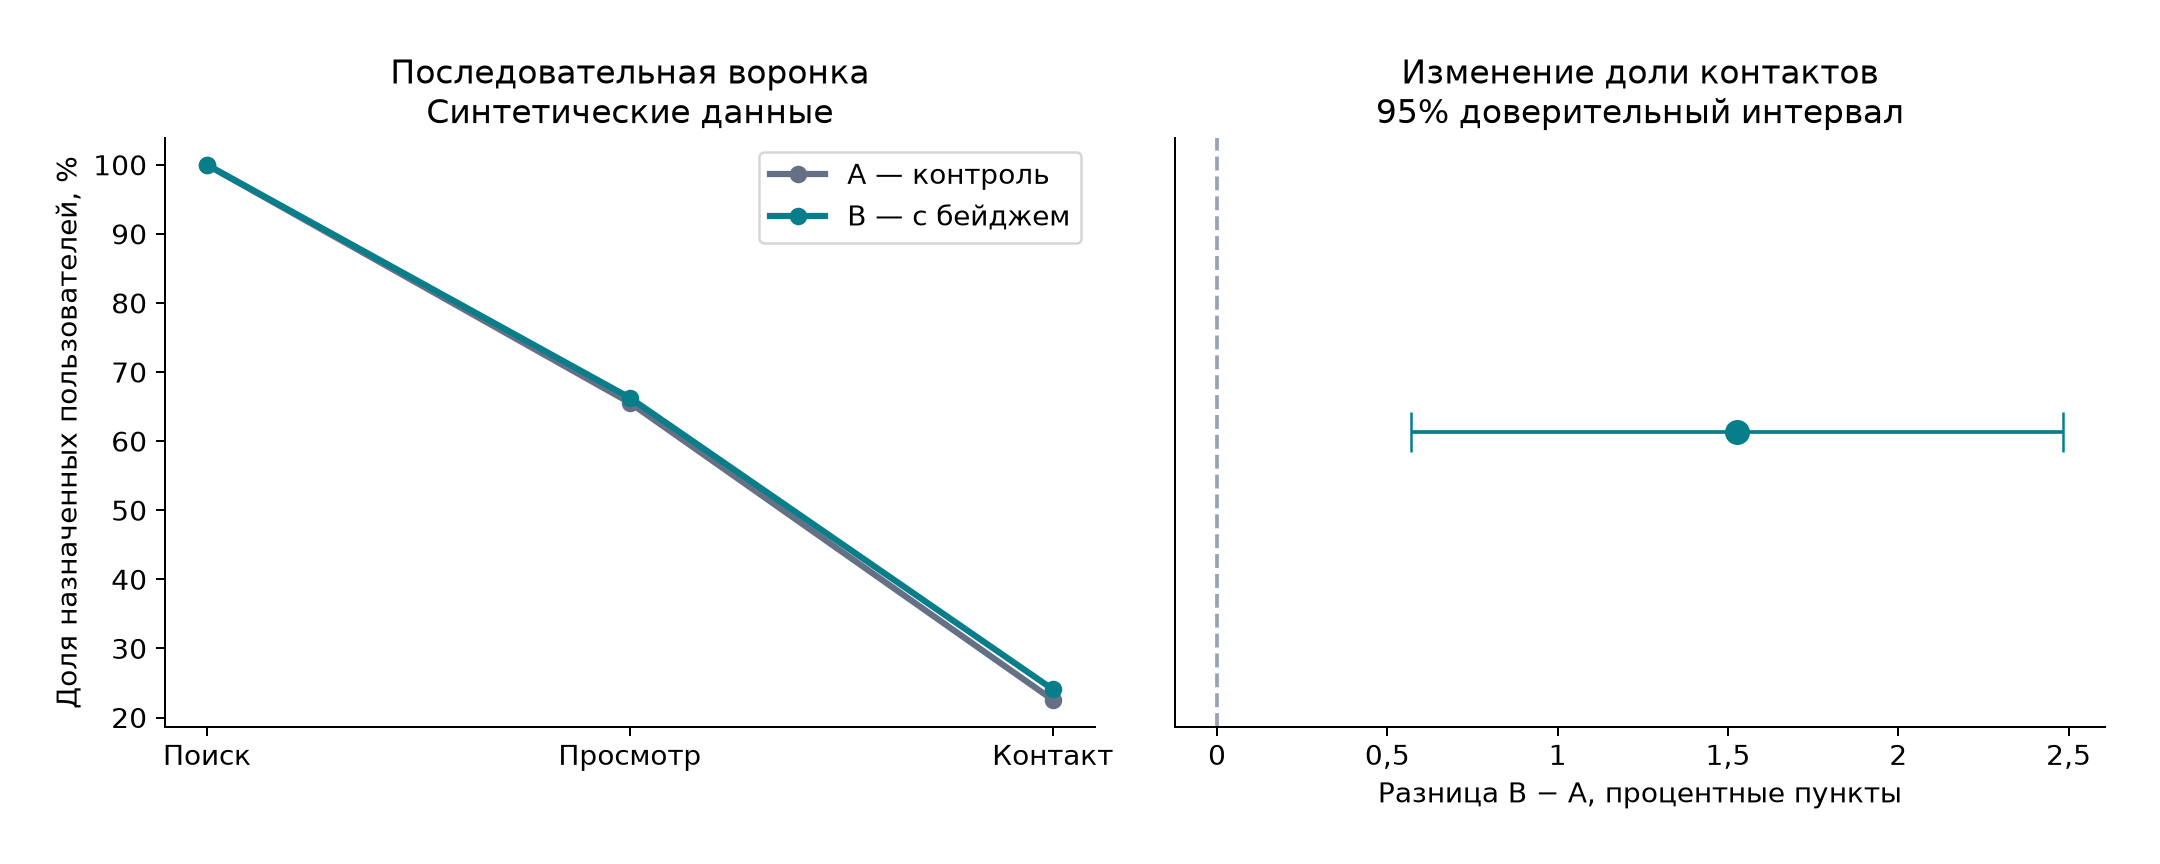

In [5]:
result = json.loads((ROOT/'reports/results.json').read_text(encoding='utf-8'))
display(pd.DataFrame(result['sample']).rename(columns={
    'variant': 'Группа', 'n': 'Пользователи', 'contacts': 'Контакты', 'complaints': 'Жалобы'}))
metric_labels = {
    'a_rate': 'Доля в группе A', 'b_rate': 'Доля в группе B', 'difference': 'Разница B − A',
    'relative_lift': 'Относительное изменение', 'ci_low': 'Нижняя граница 95% ДИ',
    'ci_high': 'Верхняя граница 95% ДИ', 'upper_one_sided_95': 'Односторонняя верхняя 95% граница',
    'pvalue': 'p-значение', 'method': 'Метод расчёта',
    'fisher_two_sided_pvalue': 'p-значение точного теста Фишера',
}
display(pd.DataFrame({'Основная метрика': result['primary'], 'Жалобы': result['guardrail']})
        .rename(index=metric_labels).fillna('—'))
print('p-значение проверки соотношения размеров групп (SRM):', result['srm_pvalue'])
print('Решение:', DECISION_LABELS[result['decision']])
display(Image(filename=str(ROOT/'reports/overview.png')))

## 5 Продуктовое решение и ограничения

Числовой итог и условия решения показаны ниже. В реальном эксперименте потребуются
аудит потерь трекинга, оценка мощности жалоб, устойчивое межустройственное назначение,
несколько сессий и учёт сетевых эффектов продавцов. Симуляция этого не проверяет.

In [6]:
display(Markdown((ROOT/'reports/decision.md').read_text(encoding='utf-8')))

# Анализ эксперимента в сервисе объявлений

**Пока не запускать в рамках симуляции**

Все пользователи и события синтетические; эффект изменения задан генератором.
Решение учитывает рост контактов и допустимый прирост жалоб.

## Решение и доказательства

Основная метрика — доля всех назначенных пользователей с контактом за 7 дней.
Контроль: 22,58%; тест: 24,10%.
Разница: **1,53 п.п.**, относительное изменение 6,76%.
95% ДИ разницы: [0,57 п.п.; 2,48 п.п.]; p-значение = 0.001792.

Жалобы на назначенного пользователя: 0,80% → 0,94%.
Верхняя односторонняя 95% граница прироста: 0,32 п.п..
Допустимый прирост задан до запуска: 0,30 п.п. Проверка ограничения: не пройдена.
Отсутствие значимости жалоб само по себе не доказывает безопасность.

Проверка соотношения размеров групп (SRM): p-значение = 0.0064.
Окна наблюдения всех пользователей завершены: да.
Расчётный объём для основной метрики: 8,554 на группу
(исходная конверсия 22%, минимальный обнаруживаемый эффект 1,8 п.п., уровень значимости 5%,
мощность 80%). Это не отдельный расчёт мощности жалоб.
Если по ограничению недостаточно точности, решение — отложить запуск независимо от основной метрики.

![Воронка и эффект](overview.png)

## Качество данных

Строк получено: 58,517; дублей: 1,426;
карантин после дедупликации: 45; принято: 57,046.
Проверены известность пользователя, тип события, время, обязательные идентификаторы
и различия в содержимом событий с одним event_id. Назначения из знаменателя не исключались.
Внесённые дефекты аддитивные. Проверка не обнаруживает события, которые вообще не были отправлены.

## Воронка и продуктовая интерпретация

Воронка требует порядка «поиск → просмотр → контакт» в одной сессии и по одному объявлению.
Основная метрика отдельно считает любой корректный контакт в окне пользователя.
Знаменатель — назначенные пользователи, а не увидевшие бейдж или связавшиеся с продавцом.
Контакт — прокси полезного действия, не сделка и не выручка. Нет данных о продаже,
ответе продавца и удовлетворённости. Нельзя пересчитывать эффект в деньги.

## Что изменится в реальном эксперименте

Нужны серверное событие контакта, мониторинг потерь доставки, устойчивое назначение
между устройствами, аудит показа бейджа, исключение ботов по правилам до рандомизации,
учёт нескольких сессий, мощности ограничения и сетевых эффектов: один продавец
может получать контакты пользователей обеих групп. Наблюдаемая успешность симуляции
не означает, что эти риски проверены.
